In [ ]:
# [Colab에서 실행할 때만] 주석을 풀고, 아래 DATA_DIR를 '/content/data'로 바꿔서 사용
# from google.colab import files
# uploaded = files.upload()
# !unzip -o -q open*.zip -d /content/data


In [2]:
# @title
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '../data'  # 팀 규칙: notebooks/에서 상대 경로 (Colab이면 '/content/data')

train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
submission = pd.read_csv(f'{DATA_DIR}/sample_submission.csv')

GENE_COLS = [c for c in train.columns if c not in ('ID', 'SUBCLASS')]
train.head()

,ID,SUBCLASS,A2M,AAAS,AADAT,AARS1,ABAT,ABCA1,ABCA2,ABCA3,...,ZNF292,ZNF365,ZNF639,ZNF707,ZNFX1,ZNRF4,ZPBP,ZW10,ZWINT,ZYX
0,TRAIN_0000,KIPAN,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
1,TRAIN_0001,SARC,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
2,TRAIN_0002,SKCM,R895R,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
3,TRAIN_0003,KIRC,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT
4,TRAIN_0004,GBMLGG,WT,WT,WT,WT,WT,WT,WT,WT,...,WT,WT,WT,WT,WT,WT,WT,WT,WT,WT


# 1) train과 test의 행 수, 열 수

In [3]:
print(f"train : {train.shape[0]:,}행 x {train.shape[1]:,}열  (ID + SUBCLASS + 유전자 {len(GENE_COLS):,}개)")
print(f"test  : {test.shape[0]:,}행 x {test.shape[1]:,}열  (ID + 유전자 {test.shape[1]-1:,}개)")
print(f"sample_submission : {submission.shape[0]:,}행 x {submission.shape[1]}열")
print('train/test 유전자 컬럼 동일 여부:', set(GENE_COLS) == set(test.columns[1:]))

train : 6,201행 x 4,386열  (ID + SUBCLASS + 유전자 4,384개)
test  : 2,546행 x 4,385열  (ID + 유전자 4,384개)
sample_submission : 2,546행 x 2열
train/test 유전자 컬럼 동일 여부: True


# 2) 결측치 여부

In [4]:
def missing_summary(df, name):
    total = df.isna().sum().sum()
    print(f"[{name}] 전체 결측치: {total}개, 결측 있는 열: {(df.isna().sum() > 0).sum()}개, "
          f"결측 있는 행: {(df.isna().sum(axis=1) > 0).sum()}개")

missing_summary(train, 'train')
missing_summary(test, 'test')

test_na = test.isna().sum()
test_na[test_na > 0].sort_values(ascending=False).to_frame('결측 개수')

[train] 전체 결측치: 0개, 결측 있는 열: 0개, 결측 있는 행: 0개
[test] 전체 결측치: 237개, 결측 있는 열: 25개, 결측 있는 행: 128개


,결측 개수
CNOT2,77
TNFAIP6,65
AK2,29
MYL1,21
RBM5,19
TMEM97,4
PTGES3,3
CCRL2,2
ATP6V1H,1
IER3,1


In [5]:
raw_test = pd.read_csv(f'{DATA_DIR}/test.csv', keep_default_na=False, dtype=str)
print('test 결측 위치의 원본 값:', pd.Series(raw_test.values[test.isna().values]).value_counts().to_dict())

test 결측 위치의 원본 값: {'': 237}


#3) 변이 값이 어떤 형태로 들어있는지(WT 외에 어떤 표기들이 있고, 각각 몇개씩인지)

In [6]:
cell_values = pd.Series(train[GENE_COLS].values.ravel())
n_cells = len(cell_values)
n_wt = (cell_values == 'WT').sum()
mutated = cell_values[cell_values != 'WT']

print(f"전체 칸: {n_cells:,}")
print(f"WT(변이 없음): {n_wt:,} ({n_wt/n_cells:.2%})")
print(f"변이 있는 칸: {len(mutated):,} ({len(mutated)/n_cells:.2%})")
print(f"  - 한 칸에 변이 여러 개(공백 구분): {mutated.str.contains(' ').sum():,}칸")
print(f"고유 값 개수(WT 제외): {mutated.nunique():,}")

전체 칸: 27,185,184
WT(변이 없음): 26,966,291 (99.19%)
변이 있는 칸: 218,893 (0.81%)
  - 한 칸에 변이 여러 개(공백 구분): 22,026칸
고유 값 개수(WT 제외): 118,846


3)-1 변이 유형별 개수

In [7]:
def mutation_type(token):
    if 'fs' in token:
        return 'Frameshift (fs)'
    if token.endswith('*'):
        return 'Nonsense (*)'
    m = re.fullmatch(r'([A-Z*])(\d+)([A-Z*])', token)
    if m:
        return 'Silent (동의)' if m.group(1) == m.group(3) else 'Missense'
    if '>' in token or '_' in token or 'del' in token or 'ins' in token:
        return 'In-frame indel'
    return 'Other'

tokens = Counter(t for v in mutated for t in v.split())
type_counts = Counter()
examples = {}
for tok, n in tokens.items():
    t = mutation_type(tok)
    type_counts[t] += n
    examples.setdefault(t, [])
    if len(examples[t]) < 3:
        examples[t].append(tok)

total_tok = sum(type_counts.values())
type_table = pd.DataFrame({
    '개수': pd.Series(type_counts),
    '비율(%)': (pd.Series(type_counts) / total_tok * 100).round(2),
    '예시': pd.Series({k: ', '.join(v) for k, v in examples.items()}),
}).sort_values('개수', ascending=False)
print(f'변이 토큰 총 {total_tok:,}개')
type_table

변이 토큰 총 255,164개


,개수,비율(%),예시
Missense,164740,64.56,"F736C, P117R, R305S"
Silent (동의),66883,26.21,"D623D, G592G, K277K"
Nonsense (*),13428,5.26,"E237*, W95*, Q110*"
Frameshift (fs),9911,3.88,"L1854fs, G692fs, C375fs"
In-frame indel,202,0.08,"1529_1530AL>AL, 142_143RL>RL, 4510_4511AL>AL"


3)-2 최다 변이

In [8]:
pd.Series(tokens).sort_values(ascending=False).head(10).to_frame('개수')

,개수
R132H,349
V600E,332
E545K,158
H1047R,154
R273C,100
R175H,76
E542K,76
R273H,72
R132C,60
R248Q,59


# 4) 아형 개수와 환자 수·비율

In [10]:
counts = train['SUBCLASS'].value_counts()
ratio = (counts / len(train) * 100).round(2)
print(f'아형 개수: {counts.shape[0]}개')
pd.DataFrame({'환자 수': counts, '비율(%)': ratio})

아형 개수: 26개


,환자 수,비율(%)
SUBCLASS,,
BRCA,786,12.68
KIPAN,515,8.31
GBMLGG,461,7.43
STES,379,6.11
KIRC,334,5.39
THCA,324,5.22
SKCM,276,4.45
PRAD,266,4.29
OV,253,4.08


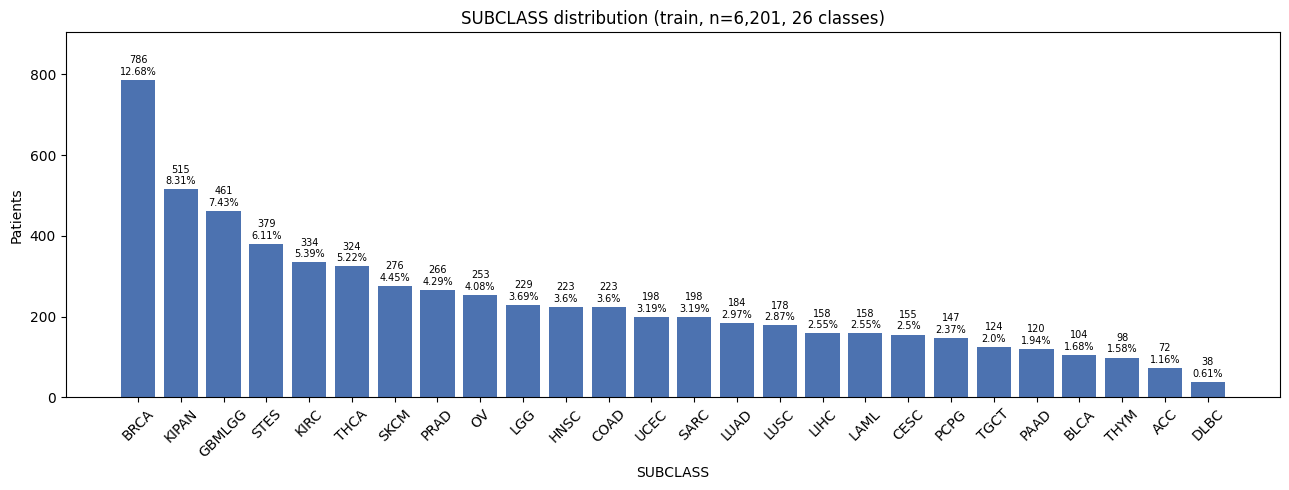

In [11]:
# @title
MIN_N = 5
fig, ax = plt.subplots(figsize=(13, 5))
colors = ['#d62728' if n < MIN_N else '#4c72b0' for n in counts.values]
bars = ax.bar(counts.index, counts.values, color=colors)
for b, n, p in zip(bars, counts.values, ratio.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 8, f'{n}\n{p}%', ha='center', va='bottom', fontsize=7)
ax.set_title(f'SUBCLASS distribution (train, n={len(train):,}, {len(counts)} classes)')
ax.set_xlabel('SUBCLASS')
ax.set_ylabel('Patients')
ax.set_ylim(0, counts.max() * 1.15)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5) 가장 적은 아형, 5명 미만 체크

In [12]:
print(f'가장 적은 아형: {counts.idxmin()} ({counts.min()}명, {ratio.min()}%)')
print(f'가장 많은 아형: {counts.idxmax()} ({counts.max()}명, {ratio.max()}%) '
      f'→ 최대/최소 {counts.max()/counts.min():.1f}배')

small = counts[counts < MIN_N]
print(f'{MIN_N}명 미만인 아형: 없음' if small.empty else f'⚠️ {MIN_N}명 미만인 아형: {small.to_dict()}')

가장 적은 아형: DLBC (38명, 0.61%)
가장 많은 아형: BRCA (786명, 12.68%) → 최대/최소 20.7배
5명 미만인 아형: 없음


# 6) 요약
1. 데이터 기본 확인

크기: train은 6,201행 × 4,386열(ID, SUBCLASS, 유전자 4,384개), test는 2,546행 × 4,385열. 두 파일의 유전자 열은 동일

결측치: train은 0개

test는 237칸(128명, 유전자 25개)이 실제 빈칸
CNOT2(77), TNFAIP6(65), AK2(29)에 집중

빈칸은 'WT'로 채우는 규칙만 사용. test의 통계값으로 채우면 데이터 누수
변이 값 형태: 99.19%가 WT(변이 없음), 변이가 있는 칸은 0.81%로 매우 희소함

22,026칸에는 변이가 여러 개 들어 있음(공백으로 구분). 피처를 만들 때 split()이 필요함

변이 유형: Missense 64.56% (R132H), Silent 26.21% (L42L), Nonsense 5.26% (R213*), Frameshift 3.88% (F144fs), In-frame indel 0.08% (1441_1442AL>AL)

많이 나온 변이: R132H(349), V600E(332), E545K(158), H1047R(154), R273C(100)

2. 타깃 확인 (SUBCLASS)

아형: 총 26개
가장 많은 아형: BRCA 786명(12.68%)
가장 적은 아형: DLBC 38명(0.61%). 최대와 최소가 약 20.7배 차이
5명 미만 아형: 없음. 5-fold Stratified K-Fold로 나눠도 fold마다 모든 아형이 들어감
이후 모델링 시 참고

평가가 Macro F1이라 DLBC, ACC, THYM 같은 소수 아형도 점수에 똑같이 반영됨. class_weight 같은 불균형 처리가 필요함
LGG와 GBMLGG, KIRC와 KIPAN은 이름이 겹쳐 서로 헷갈릴 수 있음. 혼동행렬로 확인 필요